# Notebook 00 — Setup & Veri Keşfi

**Proje:** Revisiting ML for Heart Failure Mortality (Chicco & Jurman 2020)  
**Amaç:** Veriyi indir, doğrula, keşifsel analiz yap, downstream notebook'lar için hazırla  
**Çıktılar:**
- `data/heart_failure_clinical_records_dataset.csv` (Drive'da kalıcı)
- `data/data_manifest.json` (SHA256 hash + metadata)
- `results/NB00_cohort_characteristics.csv`
- `results/NB00_correlation_matrix.csv`
- `results/figures/NB00_*.png` (5 figür)
- `logs/NB00_run_log.json`

**Çalışma süresi (tahmini):** ~3-5 dakika  
**GPU gereksinimi:** YOK — Runtime > None  

---
> ⚠️ Bu notebook'u çalıştırmadan önce:
> 1. `utils.py`'ın Drive'daki `HF_Revisit_Project/` klasöründe olduğundan emin olun
> 2. Kaggle API token'ınızın (`~/.kaggle/kaggle.json`) Colab'a yüklendiğinden emin olun

## Hücre 1 — Paket Kurulumu

## Hücre 2 — Drive Mount & utils.py Import

In [1]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 2 — Google Drive Mount + utils import
# Drive mount edilmezse tüm çıktılar oturum kapanınca kaybolur.
# ──────────────────────────────────────────────────────────────────────────────

from google.colab import drive
drive.mount('/content/drive', force_remount=False)
print("✓ Drive bağlandı.")

# utils.py'ı Python path'ine ekle
import sys
UTILS_PATH = '/content/drive/MyDrive/HF_Revisit_Project'
if UTILS_PATH not in sys.path:
    sys.path.insert(0, UTILS_PATH)

# utils'i import et
from utils import (
    set_seed, set_plot_style, create_project_structure,
    load_and_verify_data, save_data_manifest, verify_data_integrity,
    save_figure, save_csv, save_run_log, get_logger,
    DATA_DIR, RESULTS_DIR, FIGURES_DIR,
    CONTINUOUS_FEATURES, BINARY_FEATURES, TARGET,
    COLOR_ALIVE, COLOR_DEAD, COLOR_NEUTRAL, PALETTE,
    DATA_FILE, RANDOM_SEED,
)

print("✓ utils.py import edildi.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Drive bağlandı.
✓ utils.py import edildi.


## Hücre 3 — Seed, Stil, Klasör Yapısı

In [2]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 3 — Seed, Stil, Klasör Yapısı
# Her notebook'un 3. hücresi bu kalıpla başlar.
# ──────────────────────────────────────────────────────────────────────────────

import time
NB_START_TIME = time.time()

set_seed(RANDOM_SEED)        # tüm random kaynakları sabitle
set_plot_style()             # dergi kalitesi plot stili
create_project_structure()   # klasörler yoksa oluştur

logger = get_logger('NB00')
logger.info('Notebook 00 başlatıldı.')

[utils] Random seed sabitlendi → 42
[utils] Klasör yapısı hazır:
         /content/drive/MyDrive/HF_Revisit_Project/data
         /content/drive/MyDrive/HF_Revisit_Project/results
         /content/drive/MyDrive/HF_Revisit_Project/results/figures
         /content/drive/MyDrive/HF_Revisit_Project/models
         /content/drive/MyDrive/HF_Revisit_Project/logs
09:11:28 | NB00 | INFO | Notebook 00 başlatıldı.


INFO:NB00:Notebook 00 başlatıldı.


## Hücre 4 — Kaggle API Kurulumu

In [3]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 4 — Kaggle API Token Kurulumu
# kaggle.json'ı Colab'a bir kere yüklemeniz yeterli.
# Sonraki çalıştırmalarda dosya zaten /root/.kaggle/kaggle.json'da durur.
# ──────────────────────────────────────────────────────────────────────────────

import os
from pathlib import Path

KAGGLE_JSON = Path('/root/.kaggle/kaggle.json')

if not KAGGLE_JSON.exists():
    print("kaggle.json bulunamadı. Lütfen dosyayı yükleyin:")
    from google.colab import files
    uploaded = files.upload()   # kullanıcı kaggle.json'ı seçer

    KAGGLE_JSON.parent.mkdir(parents=True, exist_ok=True)
    import shutil
    shutil.move('kaggle.json', str(KAGGLE_JSON))
    KAGGLE_JSON.chmod(0o600)    # güvenlik: sadece owner okuyabilir
    print("✓ kaggle.json yerleştirildi.")
else:
    print("✓ kaggle.json zaten mevcut.")

kaggle.json bulunamadı. Lütfen dosyayı yükleyin:


Saving kaggle.json to kaggle.json
✓ kaggle.json yerleştirildi.


## Hücre 5 — Veri İndirme & SHA256 Manifest

In [4]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 5 — Veri İndirme & SHA256 Manifest
#
# İlk çalıştırma  → Kaggle'dan indir, Drive'a kaydet, manifest oluştur
# Sonraki çalıştırmalar → Drive'dan yükle, hash doğrula, manifest kontrol et
# ──────────────────────────────────────────────────────────────────────────────

import subprocess, shutil, pandas as pd
from utils import compute_sha256, save_data_manifest, MANIFEST_FILE

DATA_PATH = DATA_DIR / DATA_FILE
KAGGLE_DATASET = 'andrewmvd/heart-failure-clinical-data'

if not DATA_PATH.exists():
    logger.info('Veri bulunamadı, Kaggle\'dan indiriliyor...')

    # Geçici dizine indir
    TMP_DIR = Path('/tmp/kaggle_download')
    TMP_DIR.mkdir(exist_ok=True)

    subprocess.run(
        ['kaggle', 'datasets', 'download', '-d', KAGGLE_DATASET,
         '--unzip', '-p', str(TMP_DIR)],
        check=True
    )

    # Drive'a taşı
    downloaded = list(TMP_DIR.glob('*.csv'))
    if not downloaded:
        raise FileNotFoundError('Kaggle indirmesi başarısız — CSV bulunamadı.')

    shutil.move(str(downloaded[0]), str(DATA_PATH))
    logger.info(f'Veri Drive\'a taşındı: {DATA_PATH}')

    # İlk kez manifest oluştur
    df_raw = pd.read_csv(DATA_PATH)
    manifest = save_data_manifest(DATA_PATH, df_raw)
    logger.info(f'Manifest oluşturuldu. SHA256: {manifest["sha256"][:16]}...')

else:
    logger.info('Veri Drive\'da mevcut, hash doğrulanıyor...')

    if MANIFEST_FILE.exists():
        from utils import verify_data_integrity
        verify_data_integrity(DATA_PATH)  # eşleşmezse ValueError fırlatır
    else:
        # Manifest yoksa yeniden oluştur
        df_raw = pd.read_csv(DATA_PATH)
        manifest = save_data_manifest(DATA_PATH, df_raw)
        logger.warning('Manifest yoktu, yeniden oluşturuldu.')

print(f'\n✓ Veri hazır: {DATA_PATH}')
print(f'  Boyut: {DATA_PATH.stat().st_size / 1024:.1f} KB')

09:15:56 | NB00 | INFO | Veri bulunamadı, Kaggle'dan indiriliyor...


INFO:NB00:Veri bulunamadı, Kaggle'dan indiriliyor...


09:15:58 | NB00 | INFO | Veri Drive'a taşındı: /content/drive/MyDrive/HF_Revisit_Project/data/heart_failure_clinical_records_dataset.csv


INFO:NB00:Veri Drive'a taşındı: /content/drive/MyDrive/HF_Revisit_Project/data/heart_failure_clinical_records_dataset.csv


[utils] Manifest kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/data/data_manifest.json
        SHA256 : 9c73cea7468ff5d5...
        Boyut  : 299 satır × 13 sütun
09:15:58 | NB00 | INFO | Manifest oluşturuldu. SHA256: 9c73cea7468ff5d5...


INFO:NB00:Manifest oluşturuldu. SHA256: 9c73cea7468ff5d5...



✓ Veri hazır: /content/drive/MyDrive/HF_Revisit_Project/data/heart_failure_clinical_records_dataset.csv
  Boyut: 12.0 KB


## Hücre 6 — Veriyi Yükle & Standardize Et

In [5]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 6 — Veriyi Yükle, Kolonları Standardize Et
# load_and_verify_data() içinde COLUMN_MAP uygulanır,
# dtype'lar düzeltilir, hash tekrar doğrulanır.
# ──────────────────────────────────────────────────────────────────────────────

import numpy as np

df = load_and_verify_data(verify=True)

print('\n── İlk 5 satır ──────────────────────────────────────────────────────')
display(df.head())

print('\n── Temel bilgi ──────────────────────────────────────────────────────')
print(f'  Satır sayısı : {df.shape[0]}')
print(f'  Sütun sayısı : {df.shape[1]}')

print('\n── Veri Tipleri ─────────────────────────────────────────────────────')
print(df.dtypes.to_string())

print('\n── Eksik Değer Kontrolü ─────────────────────────────────────────────')
missing = df.isnull().sum()
if missing.sum() == 0:
    print('  ✓ Eksik değer yok.')
else:
    print(missing[missing > 0])

logger.info(f'Veri yüklendi. Shape: {df.shape}. Eksik değer: {missing.sum()}')

[utils] Veri bütünlüğü doğrulandı ✓  (9c73cea7468ff5d5...)

── İlk 5 satır ──────────────────────────────────────────────────────


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1



── Temel bilgi ──────────────────────────────────────────────────────
  Satır sayısı : 299
  Sütun sayısı : 13

── Veri Tipleri ─────────────────────────────────────────────────────
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64

── Eksik Değer Kontrolü ─────────────────────────────────────────────
  ✓ Eksik değer yok.
09:15:58 | NB00 | INFO | Veri yüklendi. Shape: (299, 13). Eksik değer: 0


INFO:NB00:Veri yüklendi. Shape: (299, 13). Eksik değer: 0


## Hücre 7 — Sınıf Dengesi (Fig 1)

[utils] Figür kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB00_class_balance.png


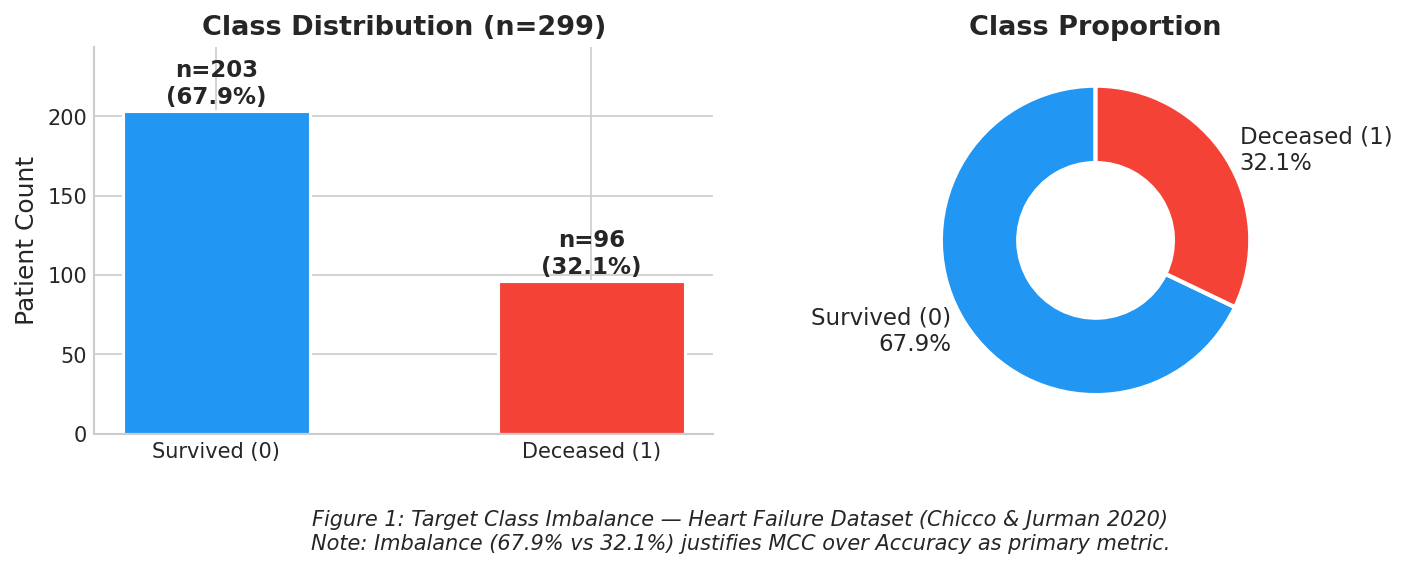

09:15:59 | NB00 | INFO | Sınıf dağılımı: Survived=203 (67.9%), Deceased=96 (32.1%)


INFO:NB00:Sınıf dağılımı: Survived=203 (67.9%), Deceased=96 (32.1%)


In [6]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 7 — Sınıf Dengesi Görselleştirme
# Bu grafik Methods bölümünde "neden MCC?" sorusunu yanıtlar.
# ──────────────────────────────────────────────────────────────────────────────

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

counts      = df[TARGET].value_counts().sort_index()
labels      = ['Survived (0)', 'Deceased (1)']
percentages = counts / counts.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# ── Sol: Bar chart ────────────────────────────────────────────────────────────
bars = axes[0].bar(
    labels, counts.values,
    color=PALETTE, edgecolor='white', linewidth=1.5, width=0.5
)
for bar, cnt, pct in zip(bars, counts.values, percentages.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f'n={cnt}\n({pct:.1f}%)',
        ha='center', va='bottom', fontsize=11, fontweight='bold'
    )
axes[0].set_title('Class Distribution (n=299)', fontweight='bold')
axes[0].set_ylabel('Patient Count')
axes[0].set_ylim(0, counts.max() * 1.2)

# ── Sağ: Pie chart ────────────────────────────────────────────────────────────
wedge_props = dict(width=0.5, edgecolor='white', linewidth=2)
axes[1].pie(
    counts.values,
    labels=[f'{l}\n{p:.1f}%' for l, p in zip(labels, percentages.values)],
    colors=PALETTE,
    autopct='',
    startangle=90,
    wedgeprops=wedge_props,
    textprops={'fontsize': 11}
)
axes[1].set_title('Class Proportion', fontweight='bold')

fig.suptitle(
    'Figure 1: Target Class Imbalance — Heart Failure Dataset (Chicco & Jurman 2020)\n'
    'Note: Imbalance (67.9% vs 32.1%) justifies MCC over Accuracy as primary metric.',
    fontsize=10, style='italic', y=0.02
)
plt.tight_layout(rect=[0, 0.06, 1, 1])

save_figure(fig, 'NB00_class_balance')
plt.show()

logger.info(f'Sınıf dağılımı: Survived={counts[0]} ({percentages[0]:.1f}%), '
            f'Deceased={counts[1]} ({percentages[1]:.1f}%)')

## Hücre 8 — Cohort Özellikleri Tablosu (Chicco Tablo 3 replikasyonu)

In [7]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 8 — Cohort Özellikleri Tablosu
# Survived vs Deceased karşılaştırması.
# Continuous: Median [IQR] + Mann-Whitney U p-değeri
# Binary:     n (%) + Chi-kare p-değeri
# Bu tablo makale Tablo 1 olacak.
# ──────────────────────────────────────────────────────────────────────────────

from scipy import stats

survived = df[df[TARGET] == 0]
deceased = df[df[TARGET] == 1]

rows = []

# ── Continuous features ───────────────────────────────────────────────────────
for feat in CONTINUOUS_FEATURES:
    s_vals = survived[feat].dropna()
    d_vals = deceased[feat].dropna()

    stat, pval = stats.mannwhitneyu(s_vals, d_vals, alternative='two-sided')

    rows.append({
        'Feature':    feat,
        'Type':       'continuous',
        'All':        f"{df[feat].median():.1f} [{df[feat].quantile(0.25):.1f}–{df[feat].quantile(0.75):.1f}]",
        'Survived (n=203)': f"{s_vals.median():.1f} [{s_vals.quantile(0.25):.1f}–{s_vals.quantile(0.75):.1f}]",
        'Deceased (n=96)':  f"{d_vals.median():.1f} [{d_vals.quantile(0.25):.1f}–{d_vals.quantile(0.75):.1f}]",
        'p-value':    f"{pval:.4f}" if pval >= 0.001 else '<0.001',
        'Stat test':  'Mann-Whitney U',
    })

# ── Binary features ───────────────────────────────────────────────────────────
for feat in BINARY_FEATURES:
    cont_table = pd.crosstab(df[feat], df[TARGET])
    chi2, pval, dof, _ = stats.chi2_contingency(cont_table)

    s_pct = survived[feat].mean() * 100
    d_pct = deceased[feat].mean() * 100
    a_pct = df[feat].mean() * 100

    rows.append({
        'Feature':    feat,
        'Type':       'binary',
        'All':        f"{df[feat].sum()} ({a_pct:.1f}%)",
        'Survived (n=203)': f"{survived[feat].sum()} ({s_pct:.1f}%)",
        'Deceased (n=96)':  f"{deceased[feat].sum()} ({d_pct:.1f}%)",
        'p-value':    f"{pval:.4f}" if pval >= 0.001 else '<0.001',
        'Stat test':  'Chi-square',
    })

table_df = pd.DataFrame(rows)

# ── Görselleştir ──────────────────────────────────────────────────────────────
print('\n── Cohort Characteristics (Chicco Tablo 3 replikasyonu) ──────────────')
display(
    table_df.style
    .set_caption('Table 1. Cohort Characteristics by Outcome')
    .apply(lambda x: ['background-color: #fff3cd' if v == '<0.001' or
                       (v not in ['continuous','binary','Mann-Whitney U','Chi-square'] and
                        v.replace('.','').replace('<','').isnumeric() and float(v.replace('<','')) < 0.05)
                       else '' for v in x], axis=1)
)

# ── Kaydet ────────────────────────────────────────────────────────────────────
save_csv(table_df, 'NB00_cohort_characteristics')
logger.info('Cohort tablosu oluşturuldu ve kaydedildi.')

# ── ÖNEMLI NOT: time-DEATH_EVENT ilişkisini vurgula ──────────────────────────
time_survived_med = survived['time'].median()
time_deceased_med = deceased['time'].median()
print(f'\n⚠️  LEAKAGE İŞARETİ: Takip süresi (time)')
print(f'   Survived → Median: {time_survived_med:.0f} gün')
print(f'   Deceased → Median: {time_deceased_med:.0f} gün')
print(f'   Bu fark ({time_survived_med - time_deceased_med:.0f} gün) Notebook 02\'de araştırılacak.')


── Cohort Characteristics (Chicco Tablo 3 replikasyonu) ──────────────


,Feature,Type,All,Survived (n=203),Deceased (n=96),p-value,Stat test
0,age,continuous,60.0 [51.0–70.0],60.0 [50.0–65.0],65.0 [55.0–75.0],<0.001,Mann-Whitney U
1,creatinine_phosphokinase,continuous,250.0 [116.5–582.0],245.0 [109.0–582.0],259.0 [128.8–582.0],0.6840,Mann-Whitney U
2,ejection_fraction,continuous,38.0 [30.0–45.0],38.0 [35.0–45.0],30.0 [25.0–38.0],<0.001,Mann-Whitney U
3,platelets,continuous,262000.0 [212500.0–303500.0],263000.0 [219500.0–302000.0],258500.0 [197500.0–311000.0],0.4256,Mann-Whitney U
4,serum_creatinine,continuous,1.1 [0.9–1.4],1.0 [0.9–1.2],1.3 [1.1–1.9],<0.001,Mann-Whitney U
5,serum_sodium,continuous,137.0 [134.0–140.0],137.0 [135.5–140.0],135.5 [133.0–138.2],<0.001,Mann-Whitney U
6,time,continuous,115.0 [73.0–203.0],172.0 [95.0–213.0],44.5 [25.5–102.2],<0.001,Mann-Whitney U
7,anaemia,binary,129 (43.1%),83 (40.9%),46 (47.9%),0.3073,Chi-square
8,diabetes,binary,125 (41.8%),85 (41.9%),40 (41.7%),1.0000,Chi-square
9,high_blood_pressure,binary,105 (35.1%),66 (32.5%),39 (40.6%),0.2141,Chi-square


[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB00_cohort_characteristics.csv
09:15:59 | NB00 | INFO | Cohort tablosu oluşturuldu ve kaydedildi.


INFO:NB00:Cohort tablosu oluşturuldu ve kaydedildi.



⚠️  LEAKAGE İŞARETİ: Takip süresi (time)
   Survived → Median: 172 gün
   Deceased → Median: 44 gün
   Bu fark (128 gün) Notebook 02'de araştırılacak.


## Hücre 9 — Feature Dağılımları (Fig 2)

[utils] Figür kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB00_feature_distributions.png


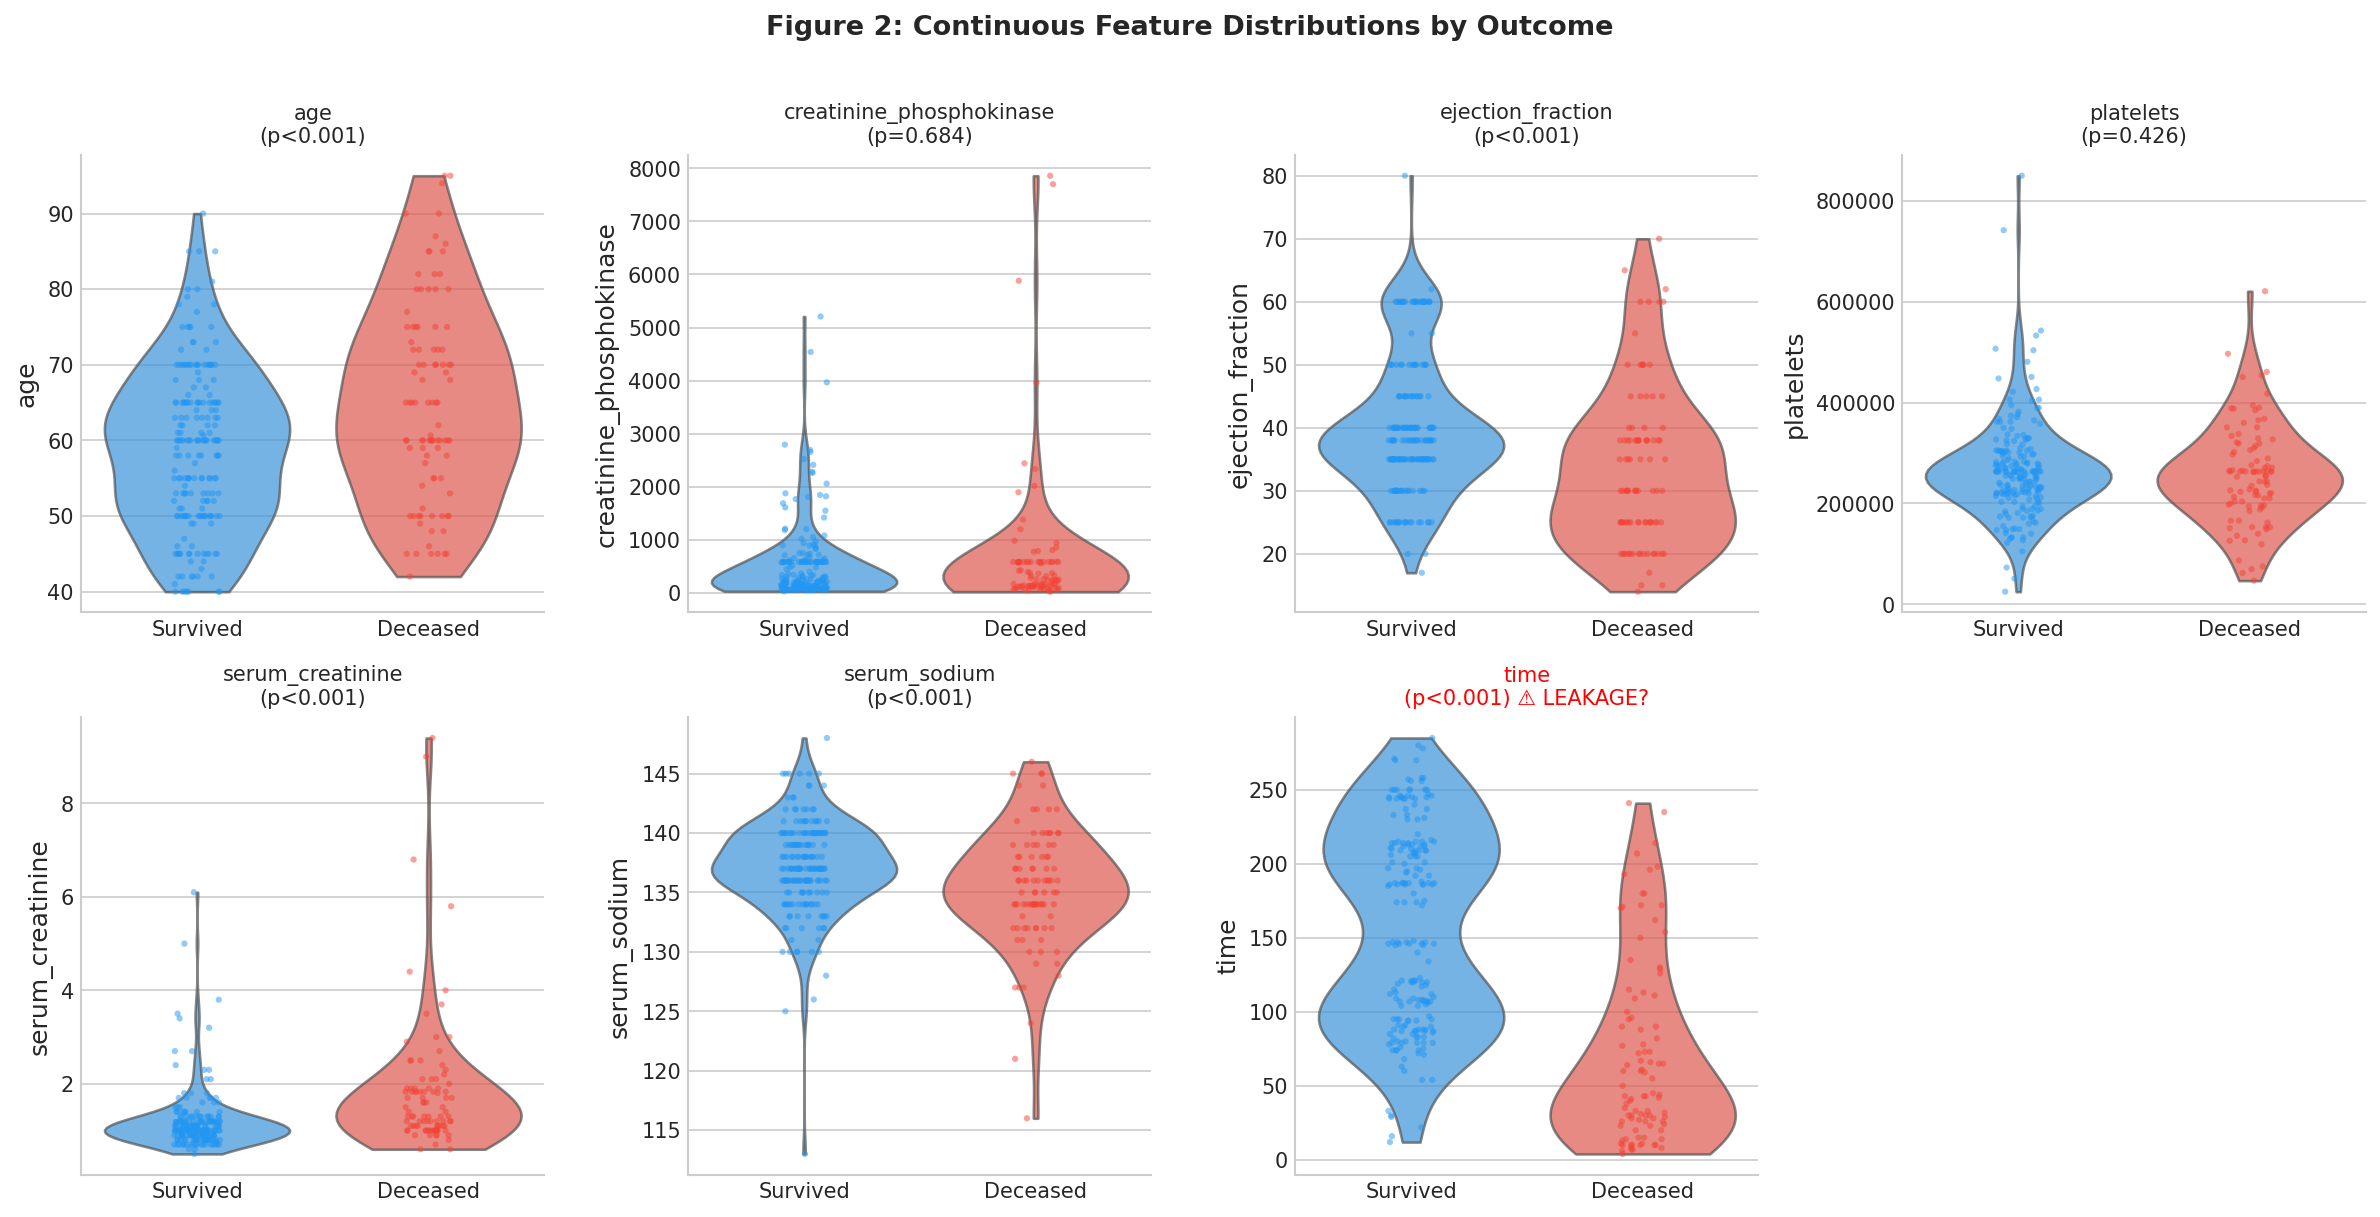

09:16:02 | NB00 | INFO | Feature dağılım grafikleri oluşturuldu.


INFO:NB00:Feature dağılım grafikleri oluşturuldu.


In [8]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 9 — Continuous Feature Dağılımları (Survived vs Deceased)
# Violin + strip plot kombinasyonu → hem dağılım hem bireysel noktalar görünür.
# ──────────────────────────────────────────────────────────────────────────────

import seaborn as sns

n_feats = len(CONTINUOUS_FEATURES)
ncols   = 4
nrows   = (n_feats + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 4))
axes = axes.flatten()

for i, feat in enumerate(CONTINUOUS_FEATURES):
    ax = axes[i]

    sns.violinplot(
        data=df, x=TARGET, y=feat, ax=ax,
        palette=PALETTE, inner=None, alpha=0.7, cut=0
    )
    sns.stripplot(
        data=df, x=TARGET, y=feat, ax=ax,
        palette=PALETTE, size=3, jitter=True, alpha=0.5
    )

    # p-değeri annotasyonu
    s_vals = survived[feat].dropna()
    d_vals = deceased[feat].dropna()
    _, pval = stats.mannwhitneyu(s_vals, d_vals, alternative='two-sided')
    pval_str = f'p={pval:.3f}' if pval >= 0.001 else 'p<0.001'

    ax.set_title(f'{feat}\n({pval_str})', fontsize=10)
    ax.set_xlabel('')
    ax.set_xticklabels(['Survived', 'Deceased'])

    # time kolonu için leakage uyarısı
    if feat == 'time':
        ax.set_title(f'{feat}\n({pval_str}) ⚠️ LEAKAGE?', fontsize=10, color='red')

# Boş eksenleri gizle
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Figure 2: Continuous Feature Distributions by Outcome',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()

save_figure(fig, 'NB00_feature_distributions')
plt.show()
logger.info('Feature dağılım grafikleri oluşturuldu.')

## Hücre 10 — Spearman Korelasyon Matrisi (Chicco Tablo 6 replikasyonu) (Fig 3)

[utils] Figür kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB00_spearman_correlation.png
[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB00_correlation_matrix.csv


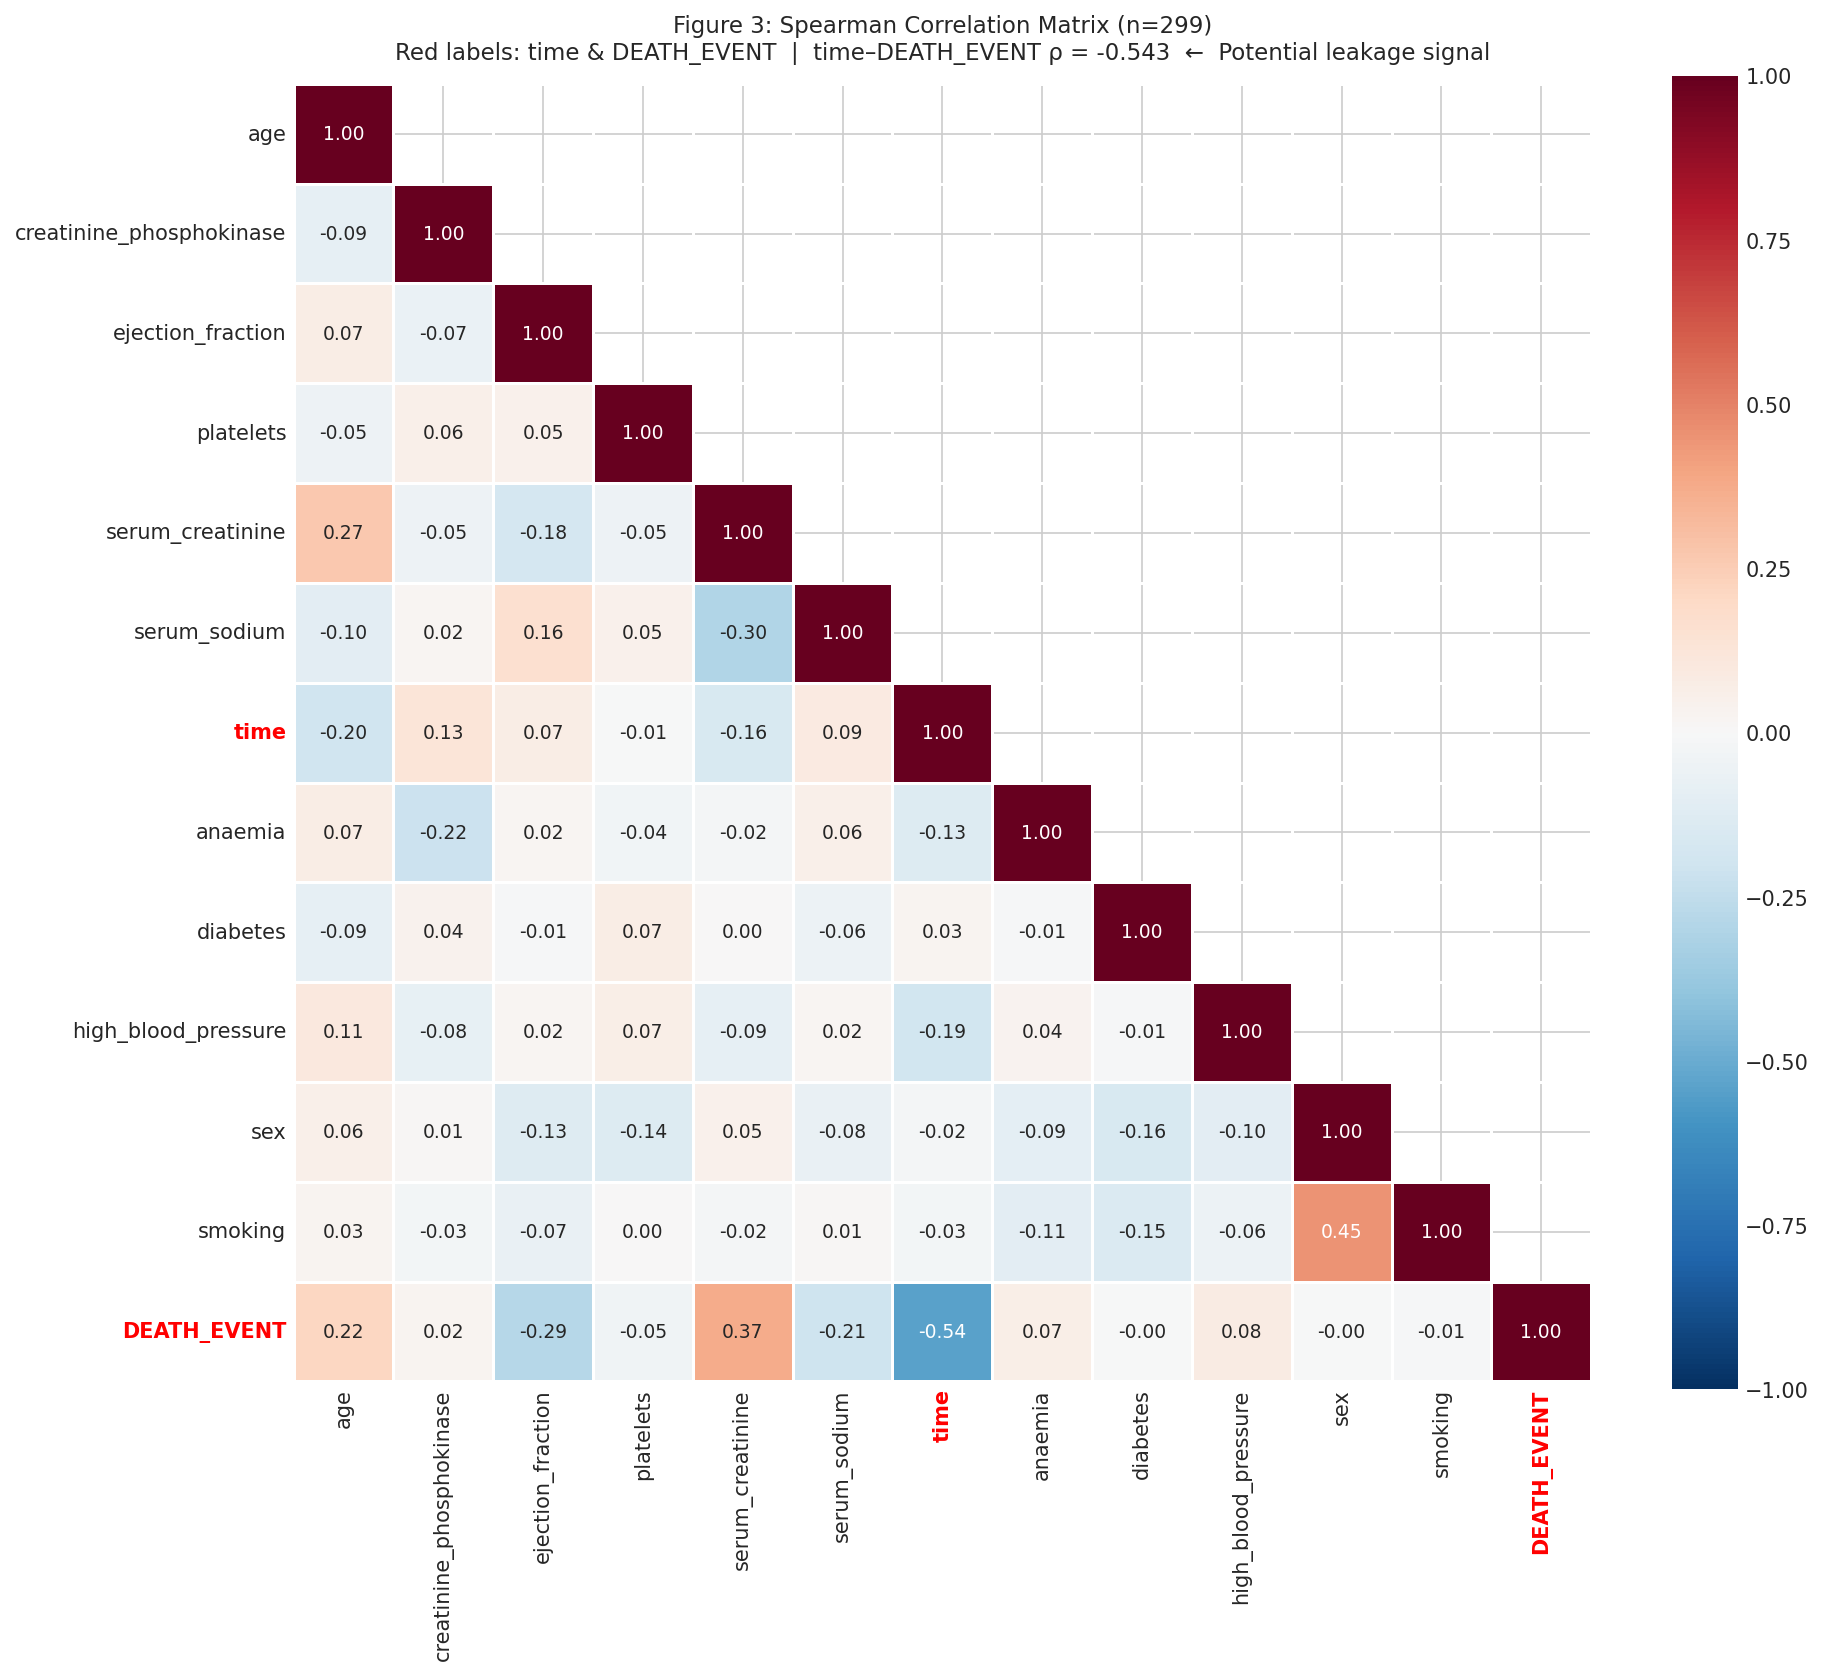

09:16:06 | NB00 | INFO | Spearman korelasyon hesaplandı. time–DEATH_EVENT ρ = -0.543


INFO:NB00:Spearman korelasyon hesaplandı. time–DEATH_EVENT ρ = -0.543



⚠️  NOTE: time–DEATH_EVENT Spearman ρ = -0.543
   Bu güçlü ilişki Notebook 02'de empirik olarak test edilecek.


In [9]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 10 — Spearman Korelasyon Matrisi
# Pearson değil Spearman — dağılımlar normal değil.
# DEATH_EVENT ve time kolonlarını özellikle vurgula.
# ──────────────────────────────────────────────────────────────────────────────

ALL_FEATURES = CONTINUOUS_FEATURES + BINARY_FEATURES + [TARGET]

corr_matrix = df[ALL_FEATURES].corr(method='spearman')

# p-değeri maskesi oluştur (p < 0.05 olanları vurgula)
from scipy.stats import spearmanr
import numpy as np

n = len(df)
pval_matrix = pd.DataFrame(
    np.ones((len(ALL_FEATURES), len(ALL_FEATURES))),
    index=ALL_FEATURES, columns=ALL_FEATURES
)
for i, c1 in enumerate(ALL_FEATURES):
    for j, c2 in enumerate(ALL_FEATURES):
        if i != j:
            _, p = spearmanr(df[c1], df[c2])
            pval_matrix.loc[c1, c2] = p

# Üst üçgeni maskele
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(13, 11))

heatmap = sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True, fmt='.2f',
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    linewidths=0.5, linecolor='white',
    ax=ax,
    annot_kws={'size': 9},
    square=True,
)

# time ve DEATH_EVENT satır/sütunlarını kırmızıyla vurgula
highlight_cols = ['time', TARGET]
for tick in ax.get_xticklabels():
    if tick.get_text() in highlight_cols:
        tick.set_color('red')
        tick.set_fontweight('bold')
for tick in ax.get_yticklabels():
    if tick.get_text() in highlight_cols:
        tick.set_color('red')
        tick.set_fontweight('bold')

time_death_corr = corr_matrix.loc['time', TARGET]

ax.set_title(
    f'Figure 3: Spearman Correlation Matrix (n=299)\n'
    f'Red labels: time & DEATH_EVENT  |  '
    f'time–DEATH_EVENT ρ = {time_death_corr:.3f}  ←  Potential leakage signal',
    fontsize=11, pad=12
)
plt.tight_layout()

save_figure(fig, 'NB00_spearman_correlation')
save_csv(corr_matrix, 'NB00_correlation_matrix')
plt.show()

logger.info(f'Spearman korelasyon hesaplandı. time–DEATH_EVENT ρ = {time_death_corr:.3f}')
print(f'\n⚠️  NOTE: time–DEATH_EVENT Spearman ρ = {time_death_corr:.3f}')
print(f'   Bu güçlü ilişki Notebook 02\'de empirik olarak test edilecek.')

## Hücre 11 — Binary Özellik Dağılımları (Fig 4)

[utils] Figür kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB00_binary_distributions.png


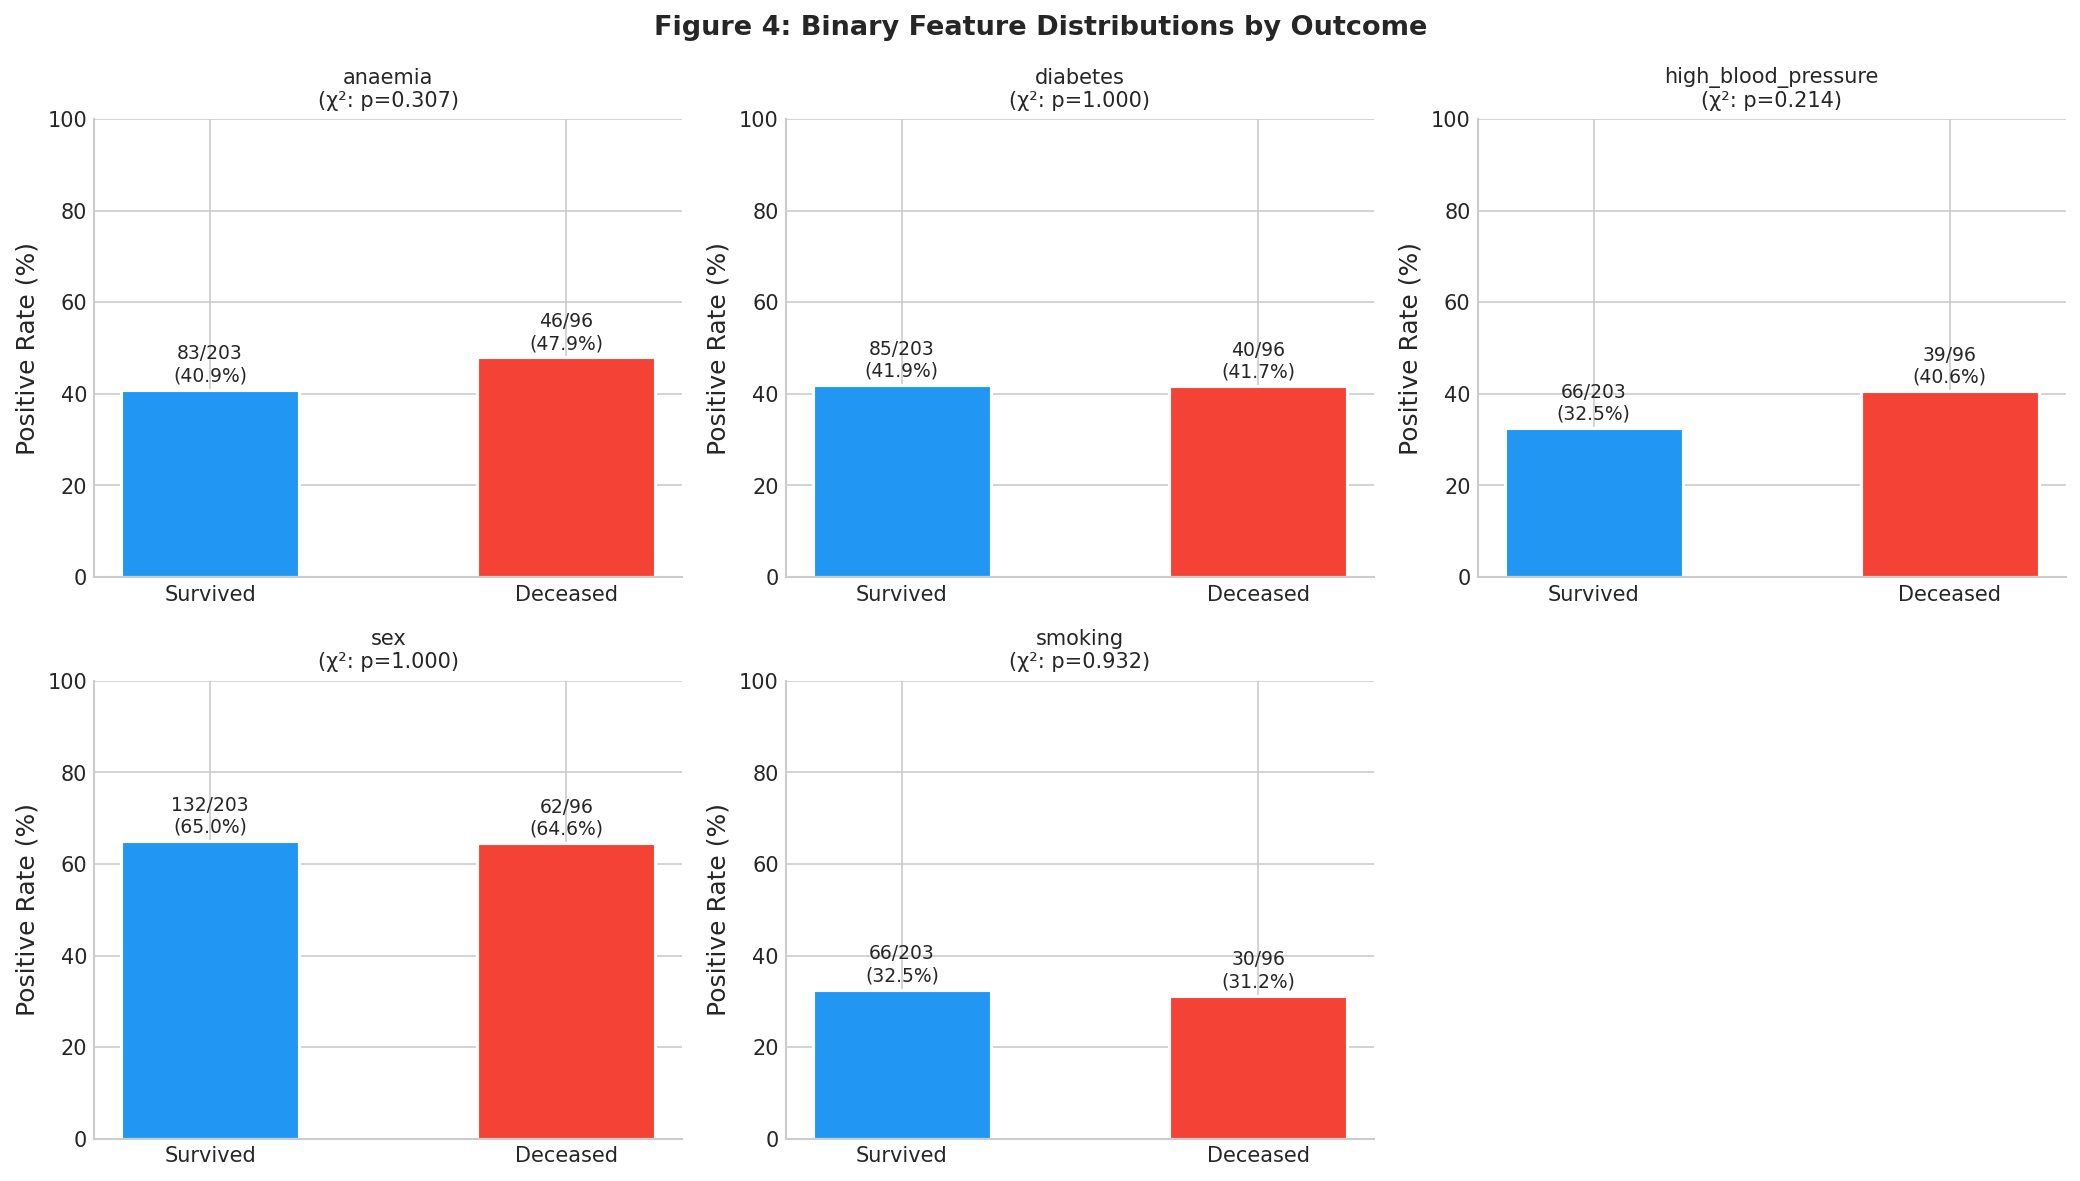

09:16:08 | NB00 | INFO | Binary feature dağılım grafikleri oluşturuldu.


INFO:NB00:Binary feature dağılım grafikleri oluşturuldu.


In [10]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 11 — Binary Feature Dağılımları
# Her binary feature için gruplandırılmış bar chart.
# ──────────────────────────────────────────────────────────────────────────────

n_bin  = len(BINARY_FEATURES)
ncols  = 3
nrows  = (n_bin + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(14, nrows * 4))
axes = axes.flatten()

for i, feat in enumerate(BINARY_FEATURES):
    ax = axes[i]

    # Her grup için pozitif oran
    group_rates = df.groupby(TARGET)[feat].mean() * 100
    group_counts = df.groupby(TARGET)[feat].sum()
    group_totals = df.groupby(TARGET)[feat].count()

    bars = ax.bar(
        ['Survived', 'Deceased'],
        group_rates.values,
        color=PALETTE, edgecolor='white', linewidth=1.5, width=0.5
    )

    for bar, cnt, total, rate in zip(
        bars, group_counts.values, group_totals.values, group_rates.values
    ):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f'{cnt}/{total}\n({rate:.1f}%)',
            ha='center', va='bottom', fontsize=9
        )

    # Chi-square p-değeri
    ct = pd.crosstab(df[feat], df[TARGET])
    _, pval, _, _ = stats.chi2_contingency(ct)
    pval_str = f'χ²: p={pval:.3f}' if pval >= 0.001 else 'χ²: p<0.001'

    ax.set_title(f'{feat}\n({pval_str})', fontsize=10)
    ax.set_ylabel('Positive Rate (%)')
    ax.set_ylim(0, 100)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Figure 4: Binary Feature Distributions by Outcome',
             fontsize=13, fontweight='bold')
plt.tight_layout()

save_figure(fig, 'NB00_binary_distributions')
plt.show()
logger.info('Binary feature dağılım grafikleri oluşturuldu.')

## Hücre 12 — Temel İstatistikler Özet Tablosu

In [11]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 12 — Tanımlayıcı İstatistikler (Supplementary Table S1)
# ──────────────────────────────────────────────────────────────────────────────

desc = df[CONTINUOUS_FEATURES].describe(percentiles=[.25, .5, .75]).T
desc.columns = ['N', 'Mean', 'Std', 'Min', 'Q1', 'Median', 'Q3', 'Max']
desc['N'] = desc['N'].astype(int)

# Skewness ve kurtosis ekle
from scipy.stats import skew, kurtosis
desc['Skewness'] = [skew(df[f]) for f in CONTINUOUS_FEATURES]
desc['Kurtosis'] = [kurtosis(df[f]) for f in CONTINUOUS_FEATURES]

print('── Tanımlayıcı İstatistikler (Continuous Features) ─────────────────────')
display(desc.round(3))

save_csv(desc, 'NB00_descriptive_statistics')
logger.info('Tanımlayıcı istatistikler kaydedildi.')

── Tanımlayıcı İstatistikler (Continuous Features) ─────────────────────


,N,Mean,Std,Min,Q1,Median,Q3,Max,Skewness,Kurtosis
age,299,60.834,11.895,40.0,51.0,60.0,70.0,95.0,0.421,-0.202
creatinine_phosphokinase,299,581.839,970.288,23.0,116.5,250.0,582.0,7861.0,4.441,24.710
ejection_fraction,299,38.084,11.835,14.0,30.0,38.0,45.0,80.0,0.553,0.021
platelets,299,263358.029,97804.237,25100.0,212500.0,262000.0,303500.0,850000.0,1.455,6.086
serum_creatinine,299,1.394,1.035,0.5,0.9,1.1,1.4,9.4,4.434,25.378
serum_sodium,299,136.625,4.412,113.0,134.0,137.0,140.0,148.0,-1.043,4.031
time,299,130.261,77.614,4.0,73.0,115.0,203.0,285.0,0.127,-1.212


[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB00_descriptive_statistics.csv
09:16:08 | NB00 | INFO | Tanımlayıcı istatistikler kaydedildi.


INFO:NB00:Tanımlayıcı istatistikler kaydedildi.


## Hücre 13 — Run Log & Notebook Sonu

In [12]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 13 — Run Log Kaydet & Notebook Özeti
# Her notebook'un son hücresi bu kalıpla biter.
# ──────────────────────────────────────────────────────────────────────────────

elapsed = time.time() - NB_START_TIME

# Önemli bulguları log'a ekle
extra_info = {
    'dataset_rows':             int(df.shape[0]),
    'dataset_cols':             int(df.shape[1]),
    'positive_rate':            float(df[TARGET].mean()),
    'missing_values':           int(df.isnull().sum().sum()),
    'time_death_spearman_rho':  float(corr_matrix.loc['time', TARGET]),
    'time_survived_median_days': float(survived['time'].median()),
    'time_deceased_median_days': float(deceased['time'].median()),
    'elapsed_seconds':          round(elapsed, 1),
    'outputs_saved': [
        'NB00_cohort_characteristics.csv',
        'NB00_correlation_matrix.csv',
        'NB00_descriptive_statistics.csv',
        'NB00_class_balance.png',
        'NB00_feature_distributions.png',
        'NB00_spearman_correlation.png',
        'NB00_binary_distributions.png',
    ]
}

save_run_log('NB00', extra=extra_info)

print('\n' + '='*65)
print('  NOTEBOOK 00 — TAMAMLANDI')
print('='*65)
print(f'  Toplam süre      : {elapsed:.1f} sn ({elapsed/60:.1f} dk)')
print(f'  Veri boyutu      : {df.shape[0]} satır × {df.shape[1]} sütun')
print(f'  Eksik değer      : {df.isnull().sum().sum()}')
print(f'  Sınıf dengesi    : %{df[TARGET].mean()*100:.1f} deceased')
print(f'  time–DEATH ρ     : {corr_matrix.loc["time", TARGET]:.3f}  ← NB02\'de araştır')
print(f'  Survived medyan  : {survived["time"].median():.0f} gün takip')
print(f'  Deceased medyan  : {deceased["time"].median():.0f} gün takip')
print('='*65)
print('  → Sonraki adım: 01_replication_chicco.ipynb')
print('='*65)

logger.info(f'Notebook 00 tamamlandı. Süre: {elapsed:.1f} sn.')

[utils] Run log kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/logs/NB00_run_log.json

  NOTEBOOK 00 — TAMAMLANDI
  Toplam süre      : 289.5 sn (4.8 dk)
  Veri boyutu      : 299 satır × 13 sütun
  Eksik değer      : 0
  Sınıf dengesi    : %32.1 deceased
  time–DEATH ρ     : -0.543  ← NB02'de araştır
  Survived medyan  : 172 gün takip
  Deceased medyan  : 44 gün takip
  → Sonraki adım: 01_replication_chicco.ipynb
09:16:08 | NB00 | INFO | Notebook 00 tamamlandı. Süre: 289.5 sn.


INFO:NB00:Notebook 00 tamamlandı. Süre: 289.5 sn.
